# Plan

**Goal:** study the data pattern / distribution of the gene-KO growth-rate time series (462 different single-cell KO with 2 seeds simulation) and compare 4 media: basal, acetate, succinate, amino acids (aa).\
The basal media simulation is set to a maximum of 12 generations; acetate, succinate, and aa are set to a maximum of 20 generations. These limits were chosen based on a previous generation-level deviation analysis.\
Some simulation are ended before pre-set maximum simulation and the resulting maximum simulation can be found in the summary file:
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_acetate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_basal_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_succinate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_with_aa_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_with_aa_seed1_2_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_3media_seed100_101_all.csv
`. \
Proposed window based on generation-difference for each media:
`/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv`

**Data:** 
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet
`, one file per medium, concatenated with a `medium` column.

Wildtype (`baseline`) is included in each medium's pool and summaries. Black dots highlight wildtype in scatter plots; the red histogram line is the equally weighted mean of the valid wildtype seed means, before plot trimming. For the seed-agreement plots only, aa wildtype seeds 1 and 2 occupy the seed 100 and 101 axes respectively; exported seed IDs remain unchanged.

**Preliminary checks**
1. Inspect shape, dtypes, NaN/inf and time range per medium. *Reason:* files come from separate simulation runs; differing lengths or missing values would bias every comparison.
2. Choose the unit of analysis: the 2 seeds of one knockout are replicates, so aggregate to one value per (medium, gene KO) before testing. *Reason:* pooling all rows treats correlated observations as independent and makes p-values far too small.

**Step 1. Per-KO summary and variability**

Preprocessing
- Restrict the time-series rows with proposed windows for each media (/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv). A run is valid if it has more than one distinct nonzero output time point; separately record whether it reached the target generation.
- Return run-validity and division-outcome counts, plus the maximum generation reached for each medium/KO/seed. Do not label a run that misses the target generation as a failed simulation; it is a valid run with division target not reached.
- Coversion: from 1/s to 1/h.
- For valid runs that do not reach the media-specific target generation, set the window growth-rate mean to zero; invalid runs (one or zero distinct nonzero output time points) have no per-seed growth-rate value and are excluded from KO means.

Plotting
- For the per-KO distribution, average the available seed means within each KO and medium. A KO is "common" when it has a non-missing per-KO mean in all four media; this does not require both seeds or completion to the maximum generation. The plotted distributions and summary table use the same common-KO set (n=? in the current output).
- The seed-to-seed scatter uses a separate inclusion rule: a KO is plotted for a medium when one seed means are present, each calculated from that seed's available time points within generations window. It does not require either seed to reach the maximum generation. The legend's n is this per-medium count of KOs with both seed means (? aa, ? acetate, ? basal, and ? succinate in the current output); it is not the common-KO count.
- Show the per-KO distribution with a box plot and overlaid points, plus the seed-1 versus seed-2 scatter plot with a 1:1 reference line. Report the common-KO count, median, and IQR.

**Step 2. Distribution plots** (histogram + KDE, violin)
- *Principle:* the histogram (shaded) with a KDE line estimates the probability density; the violin/box plot shows quartiles, outliers and density shape.
- *Reason:* KDE/violin reveal multimodality. Use `common_norm=False` so each medium is normalised on its own.

**Step 3. Temporal pattern**
- Plot mean +/- IQR growth rate vs time per medium; normalise time to 0-1 if cell cycle length differs.
- *Principle:* aggregate over seeds and knockouts at each time point.
- *Reason:* the data are time series, so media may differ in dynamics (initial transient, steady state, variability over time), not only overall distribution. Median/IQR are robust to outlier simulations.

**Expected output:** compact per-KO summary and plots, test and effect-size table, time-course plot, cross-medium correlation matrix, and a short interpretation of how the 4 media differ./
Output directory: `/user/home/il22158/work/vEcoli/reading/results/pattern`

# Code

medium                             basal        acetate      succinate  \
n_rows                     426707.000000  428305.000000  483781.000000   
n_gene                        463.000000     360.000000     343.000000   
n_variant                      94.000000       2.000000       2.000000   
n_seed                          2.000000       2.000000       2.000000   
configured_max_generation      12.000000      20.000000      20.000000   
max_generation_observed        12.000000      20.000000      20.000000   
n_nan                           0.000000       0.000000       0.000000   
n_inf                           0.000000       0.000000       0.000000   
n_neg                         183.000000      58.000000       6.000000   
n_zero                       7910.000000    6837.000000    8215.000000   
t_min                           0.000000       0.000000       0.000000   
t_max                       66940.000000   78859.000000   90878.000000   
gr_min                         -0.0022

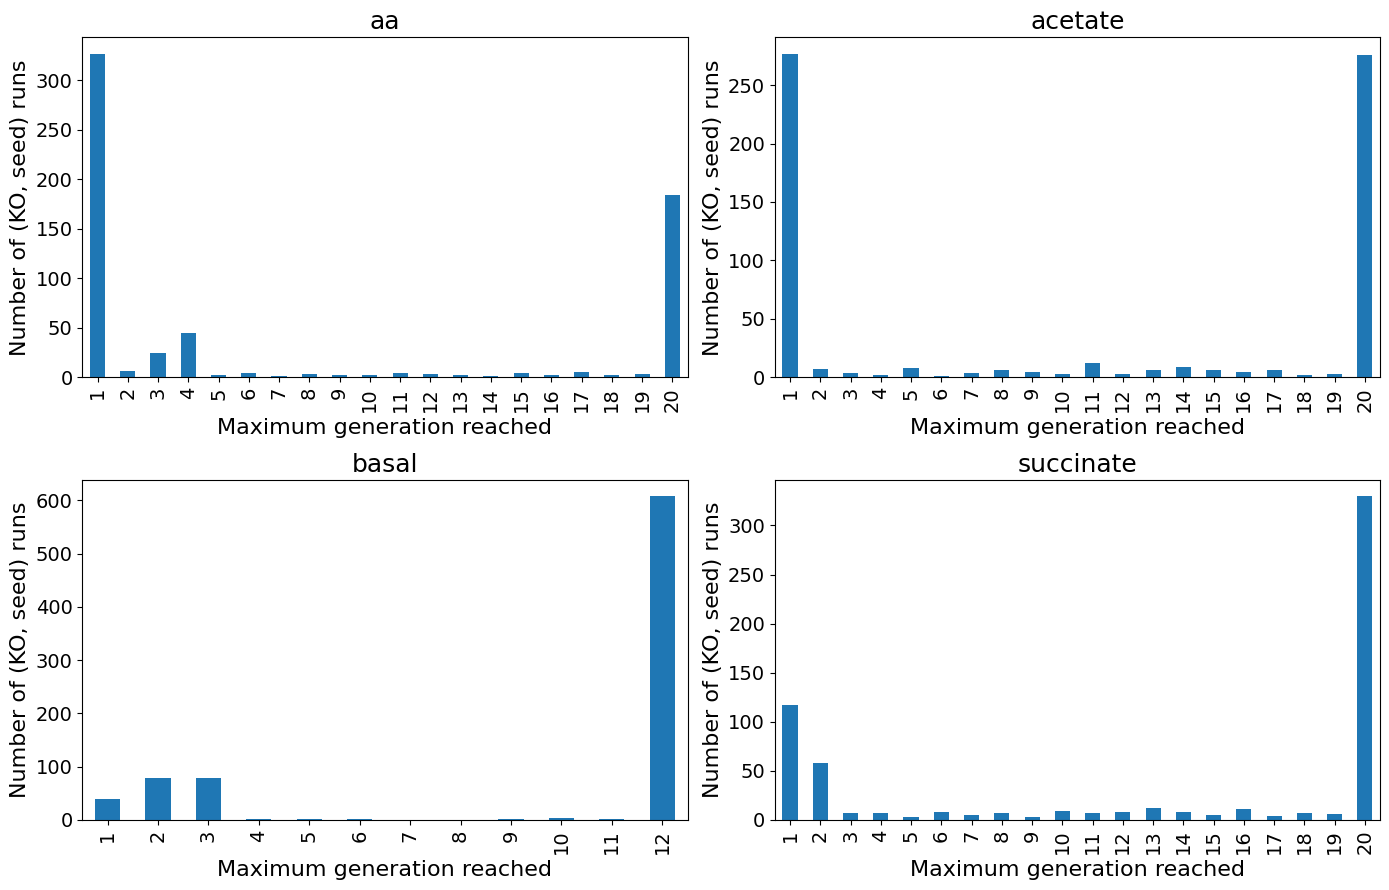

In [1]:
"""Step 0: Preliminary analysis"""
import pandas as pd, numpy as np

base = "/user/home/il22158/work/vEcoli/reading/results/growth_rate/"
files = {
    "basal":     "growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet",
    "acetate":   "growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet",
    "succinate": "growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet",
    "aa":        "growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet",
}
summary_files = {m: base + f.replace("timeseries", "summary").replace(".parquet", ".csv")
                 for m, f in files.items()}

GENE = "label"                 # e.g. "KO: EG10001"
SEED = "lineage_seed"
GEN  = "generation"
TIME = "time"
VAL  = "listeners__mass__instantaneous_growth_rate"
MASS = "listeners__mass__dry_mass"
MAX_GENERATION = {"basal": 12, "aa": 20, "acetate": 20, "succinate": 20}

dfs = {m: pd.read_parquet(base + f) for m, f in files.items()}
WILDTYPE = "baseline"
wildtype_files = [
    "growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet",
    "growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet",
]
wildtype_projects = {
    "wildtype_basal": "basal", "wildtype_acetate": "acetate",
    "wildtype_succinate": "succinate", "wildtype_with_aa_s1-5": "aa",
}
wt = pd.concat([pd.read_parquet(base + f) for f in wildtype_files], ignore_index=True)
if set(wt["project"]) != set(wildtype_projects) or set(wt[GENE]) != {WILDTYPE}:
    raise ValueError("Unexpected wildtype projects or labels")
wt["medium"] = wt["project"].map(wildtype_projects)
for m in dfs:
    if WILDTYPE in set(dfs[m][GENE]):
        raise ValueError(f"Wildtype label already present in {m} knockout data")
    w = wt[wt["medium"] == m].drop(columns="medium")
    expected_seeds = {1, 2} if m == "aa" else {100, 101}
    if set(w[SEED]) != expected_seeds:
        raise ValueError(f"Unexpected wildtype seeds in {m}: {sorted(w[SEED].unique())}")
    dfs[m] = pd.concat([dfs[m], w], ignore_index=True)

def seed_plot_values(per_seed):
    plot_values = per_seed.copy()
    aa_wt = (plot_values["medium"] == "aa") & (plot_values[GENE] == WILDTYPE)
    plot_values.loc[aa_wt, SEED] = plot_values.loc[aa_wt, SEED].map({1: 100, 2: 101})
    return plot_values

# Check 1: shape, dtypes, NaN/inf, time range per medium
rows = []
for m, d in dfs.items():
    v = d[VAL]
    rows.append({
        "medium": m,
        "n_rows": len(d),
        "n_gene": d[GENE].nunique(),
        "n_variant": d["variant"].nunique(),
        "n_seed": d[SEED].nunique(),
        "configured_max_generation": MAX_GENERATION[m],
        "max_generation_observed": d[GEN].max(),
        "n_nan": v.isna().sum(),
        "n_inf": np.isinf(v).sum(),
        "n_neg": (v < 0).sum(),
        "n_zero": (v == 0).sum(),   # includes the t=0 rows of each generation
        "t_min": d[TIME].min(),
        "t_max": d[TIME].max(),
        "gr_min": v.min(),
        "gr_median": v.median(),
        "gr_max": v.max(),
    })
print(pd.DataFrame(rows).set_index("medium").T)

# Summary files (maximum simulated generation)
for m, p in summary_files.items():
    s = pd.read_csv(p)
    print(f"\n{m} summary:", s.shape)
    print(s.head(3))
for f in wildtype_files:
    s = pd.read_csv(base + f.replace("timeseries", "summary").replace(".parquet", ".csv"))
    print(f"\n{f} summary:")
    print(s)

# Combine usable growth-rate records and exclude constructed time-zero rows.
df = pd.concat([d.assign(medium=m) for m, d in dfs.items()], ignore_index=True)
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=[VAL])
df = df[df[TIME] > 0].copy()

raw = pd.concat([d.assign(medium=m) for m, d in dfs.items()], ignore_index=True)
raw["_t"] = raw[TIME].where((raw[TIME] > 0) & np.isfinite(raw[VAL]))  # NaN -> not counted as output
sim_status = (raw.groupby(["medium", GENE, SEED])
                .agg(n_output_timepoints=("_t", "nunique"), max_gen=(GEN, "max"))
                .reset_index())
sim_status["valid_run"] = sim_status["n_output_timepoints"] > 1
sim_status["target_max_gen"] = sim_status["medium"].map(MAX_GENERATION)
sim_status["reached_target_generation"] = sim_status["max_gen"] >= sim_status["target_max_gen"]
sim_status["division_outcome"] = np.where(
    sim_status["reached_target_generation"], "reached_target_generation", "did_not_reach_target_generation"
)
sim_status["run_status"] = np.where(sim_status["valid_run"], "valid_run", "invalid_run")
print("\nRun validity (>1 distinct nonzero output time point):")
print(sim_status.groupby("medium")["valid_run"].agg(valid_runs="sum", total_runs="size"))
print("\nGeneration outcome, reported separately from run validity:")
print(pd.crosstab(sim_status["medium"], sim_status["division_outcome"]))

# Generations actually reached per (knockout, seed)
for m, d in dfs.items():
    g = d.groupby([GENE, SEED])[GEN].max()
    print(f"\n{m}: max generation reached per (KO, seed)")
    print(g.value_counts().sort_index())

# Check 2: average over valid seeds, then one value per (medium, gene KO).
per_seed = (df.groupby(["medium", GENE, SEED])
              .agg(mean=(VAL, "mean"), n_output_timepoints=(TIME, "nunique")).reset_index())
per_seed["valid_run"] = per_seed["n_output_timepoints"] > 1
per_ko = (per_seed[per_seed["valid_run"]]
          .groupby(["medium", GENE])["mean"].mean().reset_index())

print(per_ko.groupby("medium")[GENE].nunique())
wide = per_ko.pivot(index=GENE, columns="medium", values="mean")
print("KOs missing per medium:\n", wide.isna().sum())
print(wide.describe())

# Visualization - Accumulated bar plot for distribution of maximum generation reached per (KO, seed) across media
import os, matplotlib.pyplot as plt
OUT0 = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT0, exist_ok=True)
gen_counts = sim_status[sim_status["valid_run"]].pivot_table(index="max_gen", columns="medium", values=SEED, aggfunc="size", fill_value=0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, gen_counts.columns):
    c = gen_counts[m].reindex(range(1, 13), fill_value=0) if m == "basal" else gen_counts[m]
    c.plot(kind="bar", ax=ax)
    ax.set_title(m, fontsize=18); ax.set_xlabel("Maximum generation reached", fontsize=16)
    ax.set_ylabel("Number of (KO, seed) runs", fontsize=16); ax.tick_params(labelsize=14)
plt.tight_layout(); plt.savefig(f"{OUT0}/step0_max_generation_stacked_bar.png", dpi=150); plt.show()

# File save - save the invalid/valid runs per KO, seed, media
sim_status.to_csv(f"{OUT0}/step0_run_status_per_KO_seed_media.csv", index=False)


Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                627            72                    203   
acetate           645            72                    331   
basal             814           112                    612   
succinate         622            62                    398   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                        424         699            0.896996  
acetate                   314         717            0.899582  
basal                     202         926            0.879050  
succinate                 224         684            0.909357  

Growth rate for 250 common KOs and wildtype (when present):
           count    median       IQR
medium                              
basal      250.0  0.7867

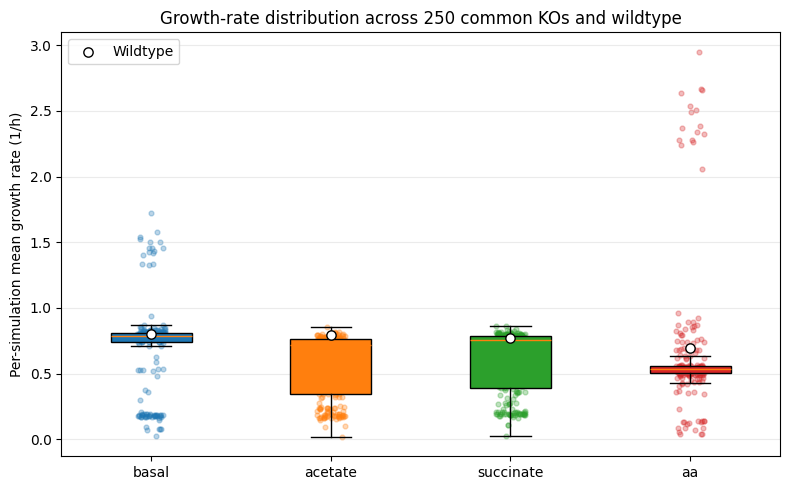

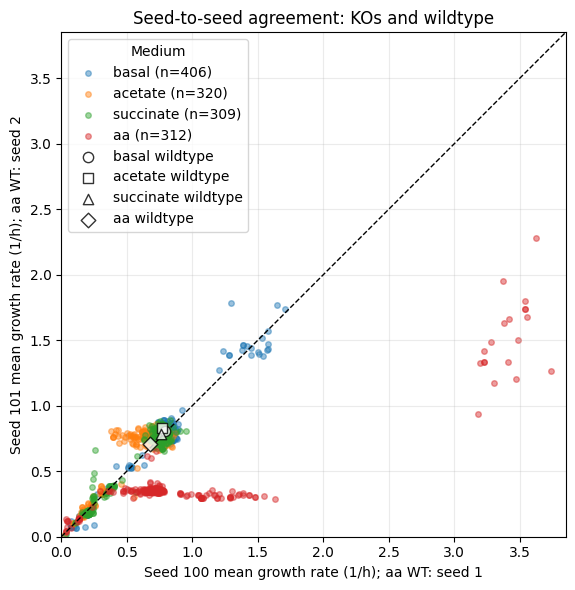

In [17]:
# Step 1a: per-KO growth patterns and seed agreement using all timepoints
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

medium_order = ["basal", "acetate", "succinate", "aa"]

# df contains finite growth-rate values at nonzero timepoints.
# Convert growth rate from 1/s to 1/h.
d = df.copy()
d[VAL] = d[VAL] * 3600

run_mean = (
    d.groupby(["medium", GENE, SEED])
     .agg(
         run_mean=(VAL, "mean"),
         n_run_points=(TIME, "nunique"),
     )
     .reset_index()
)

# Run validity is independent of whether the target generation was reached.
run_info = sim_status[
    ["medium", GENE, SEED, "n_output_timepoints", "max_gen"]
].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = (
    run_info["max_gen"] >= run_info["target_max_gen"]
)
run_info["division_success"] = (
    run_info["valid_run"] & run_info["reached_target_generation"]
)

ps = run_info.merge(
    run_mean,
    on=["medium", GENE, SEED],
    how="left",
)
ps["n_run_points"] = ps["n_run_points"].fillna(0).astype(int)

missing_mean = ps["valid_run"] & ps["run_mean"].isna()
if missing_mean.any():
    raise ValueError("A valid simulation has no growth-rate data")

ps["mean"] = ps["run_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1a_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = (
    ps["valid_run"] & ~ps["reached_target_generation"]
)
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = (
    outcomes["valid_runs"] / outcomes["total_runs"]
)
outcomes.to_csv(f"{OUT}/step1a_simulation_outcomes.csv")

print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()

ko_status["n_invalid_seeds"] = (
    ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
)
ko_status["n_valid_seeds_below_target"] = (
    ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
)
ko_status["status"] = np.select(
    [
        ko_status["n_valid_seeds"] == 0,
        ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
        ko_status["n_division_successes"] == 0,
    ],
    [
        "no_valid_run",
        "all_seeds_reached_target",
        "no_seed_reached_target",
    ],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1a_per_KO_simulation_status.csv", index=False)

# Average available valid-seed means within each KO and medium.
ko = (
    ps.groupby(["medium", GENE])["mean"]
      .mean()
      .reset_index()
)
ko.to_csv(f"{OUT}/step1a_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1a_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1a_per_KO_summary.csv")

print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)
for i, (patch, medium) in enumerate(
    zip(box["boxes"], medium_order),
    start=1,
):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(
        i + jitter,
        common[medium],
        color=colors[i - 1],
        s=12,
        alpha=0.3,
    )
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)

ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(
    index=["medium", GENE],
    columns=SEED,
    values="mean",
)
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")

seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))

for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has valid means for both seeds, so it is not plotted")
        continue

    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(
        pair[seed_columns[0]],
        pair[seed_columns[1]],
        color=colors[i],
        s=16,
        alpha=0.45,
        label=f"{medium} (n={len(pair)})",
    )

for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, alpha = 0.8,
                   facecolor="white", edgecolor="black", s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)

ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(low, high),
    ylim=(low, high),
    xlabel=f"Seed {seed_columns[0]} mean growth rate (1/h); aa WT: seed 1",
    ylabel=f"Seed {seed_columns[1]} mean growth rate (1/h); aa WT: seed 2",
    title="Seed-to-seed agreement: KOs and wildtype",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_seed_agreement.png", dpi=180)
plt.show()

Medium: basal, Window: (3, 10), Max generation for filter zero-growth: 10
Medium: acetate, Window: (3, 10), Max generation for filter zero-growth: 10
Medium: succinate, Window: (4, 11), Max generation for filter zero-growth: 11
Medium: aa, Window: (6, 13), Max generation for filter zero-growth: 13
Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                627            72                    203   
acetate           645            72                    331   
basal             814           112                    612   
succinate         622            62                    398   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                        424         699            0.896996  
acetate                   314         717           

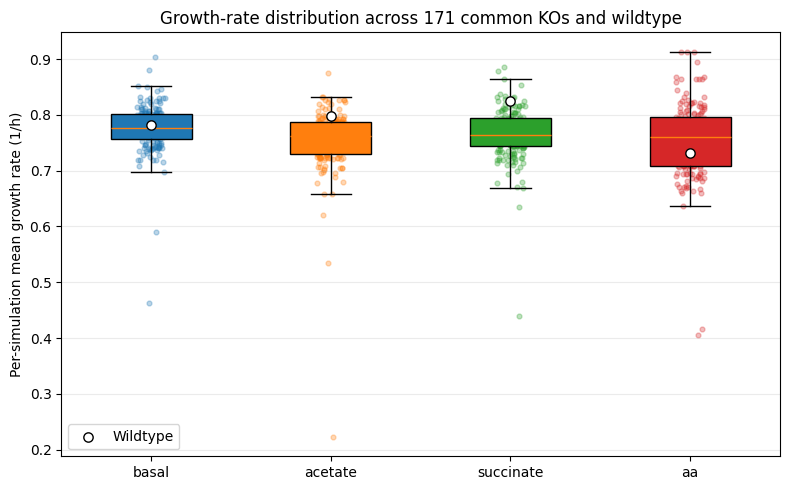

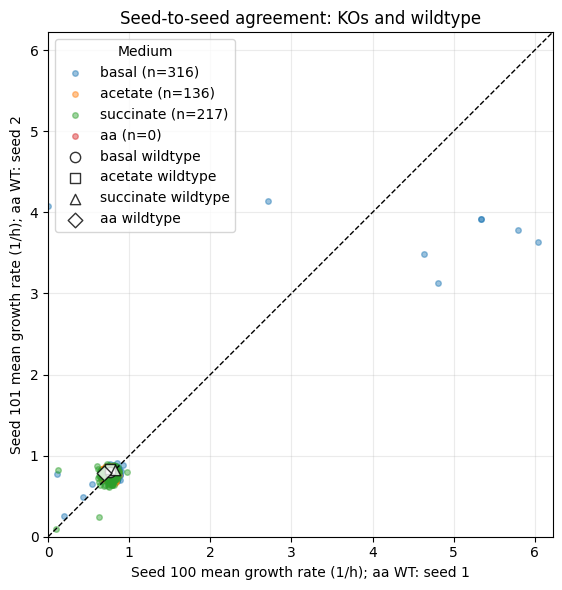

In [16]:
# Step 1b: per-KO growth patterns and seed agreement (growth rate in 1/h) with selected windows
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

WINDOWS_FILE = "/user/home/il22158/work/vEcoli/reading/results/tdi/tdi_summary_462KO_4media_composite_tdi.csv"
WINDOW_MEDIA = {"basal": "basal", "with_aa": "aa", "acetate": "acetate", "succinate": "succinate"}
medium_order = ["basal", "acetate", "succinate", "aa"]

window_table = pd.read_csv(WINDOWS_FILE)
window_table = window_table[window_table["Media"].isin(WINDOW_MEDIA)]
window_table["medium"] = window_table["Media"].map(WINDOW_MEDIA)
if window_table["medium"].isna().any():
    raise ValueError("TDI window file contains a medium not used in this analysis")
window_bounds = {}
for _, row in window_table.iterrows():
    start, end = map(int, row["Proposed generation window"].split("-"))
    window_bounds[row["medium"]] = (start, end)
if set(window_bounds) != set(medium_order):
    raise ValueError(f"Expected TDI windows for {medium_order}, found {sorted(window_bounds)}")
if set(df["medium"].unique()) != set(medium_order):
    raise ValueError(f"Unexpected input media: {sorted(df['medium'].unique())}")

d = df.copy()
d[VAL] = d[VAL] * 3600
d["window_start"] = d["medium"].map({m: bounds[0] for m, bounds in window_bounds.items()})
d["window_end"] = d["medium"].map({m: bounds[1] for m, bounds in window_bounds.items()})
MAX_GENERATION = {m: d.loc[d["medium"] == m, "window_end"].iloc[0] for m in medium_order}

for i in range(len(medium_order)):
    print(f"Medium: {medium_order[i]}, Window: {window_bounds[medium_order[i]]}, Max generation for filter zero-growth: {MAX_GENERATION[medium_order[i]]}")

in_window = d[(d[GEN] >= d["window_start"]) & (d[GEN] <= d["window_end"])]
window_mean = (in_window.groupby(["medium", GENE, SEED])
                 .agg(window_mean=(VAL, "mean"), n_window_points=(TIME, "nunique")).reset_index())

# Run validity comes from Step 0 (computed on the raw data, so runs with only t=0 rows are kept as invalid).
run_info = sim_status[["medium", GENE, SEED, "n_output_timepoints", "max_gen"]].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = run_info["max_gen"] >= run_info["target_max_gen"]
run_info["division_success"] = run_info["valid_run"] & run_info["reached_target_generation"]
ps = run_info.merge(window_mean, on=["medium", GENE, SEED], how="left")
ps["n_window_points"] = ps["n_window_points"].fillna(0).astype(int)
missing_window = ps["division_success"] & ps["window_mean"].isna()
if missing_window.any():
    raise ValueError("A valid simulation reached its target generation but has no data in its proposed window")
# OPTIONAL (disabled): zero-fill valid runs that stop before the target generation
# ps["mean"] = np.where(
#     ~ps["valid_run"], np.nan,
#     np.where(ps["reached_target_generation"], ps["window_mean"], 0.0),
# )
ps["mean"] = ps["window_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = ps["valid_run"] & ~ps["reached_target_generation"]
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = outcomes["valid_runs"] / outcomes["total_runs"]
outcomes.to_csv(f"{OUT}/step1_simulation_outcomes.csv")
print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()
ko_status["n_invalid_seeds"] = ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
ko_status["n_valid_seeds_below_target"] = ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
ko_status["status"] = np.select(
    [ko_status["n_valid_seeds"] == 0,
     ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
     ko_status["n_division_successes"] == 0],
    ["no_valid_run", "all_seeds_reached_target", "no_seed_reached_target"],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1_per_KO_simulation_status.csv", index=False)

ko = ps.groupby(["medium", GENE])["mean"].mean().reset_index()
ko.to_csv(f"{OUT}/step1_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1_per_KO_summary.csv")
print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)

for i, (patch, medium) in enumerate(zip(box["boxes"], medium_order), start=1):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(i + jitter, common[medium], color=colors[i - 1], s=12, alpha=0.3)
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)
ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(index=["medium", GENE], columns=SEED, values="mean")
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")
seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))
for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has a window mean in both seeds, so it is not plotted")
        continue
    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], color=colors[i],
               s=16, alpha=0.45, label=f"{medium} (n={len(pair)})")
for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, facecolor="white", edgecolor="black", alpha = 0.8,
                   s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)
ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(xlim=(low, high), ylim=(low, high),
       xlabel=f"Seed {seed_columns[0]} mean growth rate (1/h); aa WT: seed 1",
       ylabel=f"Seed {seed_columns[1]} mean growth rate (1/h); aa WT: seed 2",
       title="Seed-to-seed agreement: KOs and wildtype")
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_seed_agreement.png", dpi=180)

/tmp/ipykernel_3994203/2726913938.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


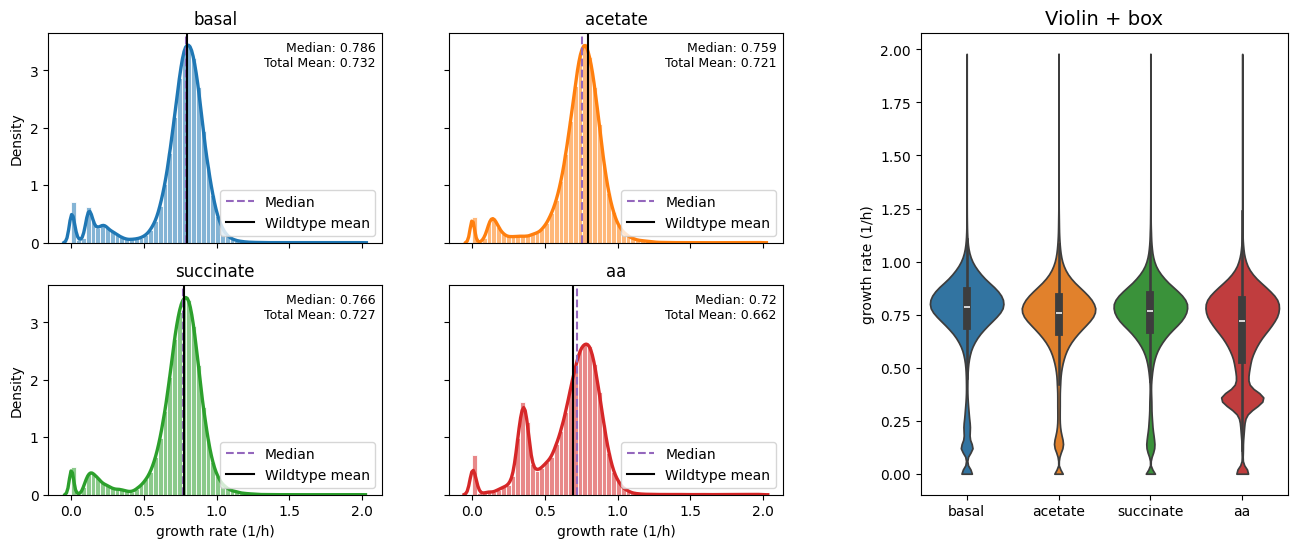

In [23]:
# Step 2: distribution of growth rate (1/h), all time points
# median point is indicated by a dashed line in the histograms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

media = ["basal", "acetate", "succinate", "aa"]
palette = dict(zip(media, sns.color_palette("tab10", 4)))
LAB = "growth rate (1/h)"
central_line_color = sns.color_palette("tab10", 5)[-1]

# All time points (t > 0) of valid runs; trim rare extremes for plotting.
pts = d[d[TIME] > 0].merge(
    ps.loc[ps["valid_run"], ["medium", GENE, SEED]],
    on=["medium", GENE, SEED],
)
wildtype_mean = (pts[pts[GENE] == WILDTYPE].groupby(["medium", SEED])[VAL]
                 .mean().groupby("medium").mean())
lo, hi = pts[VAL].quantile([.005, .995])
pts = pts[(pts[VAL] >= lo) & (pts[VAL] <= hi)]
bin_edges = np.linspace(lo, hi, 61)

# Two main plots in one row: per-medium histograms on the left, violin plot on the right.
fig = plt.figure(figsize=(16, 6))
outer = fig.add_gridspec(1, 2, width_ratios=[2, 1], wspace=0.25)
hist_axes = outer[0, 0].subgridspec(2, 2).subplots(sharex=True, sharey=True)
violin_ax = fig.add_subplot(outer[0, 1])

for ax, medium in zip(hist_axes.flat, media):
    medium_pts = pts[pts["medium"] == medium]
    median = medium_pts[VAL].median()
    mean = medium_pts[VAL].mean()

    sns.histplot(
        data=medium_pts,
        x=VAL,
        bins=bin_edges,
        stat="density",
        element="bars",
        fill=True,
        alpha=0.55,
        color=palette[medium],
        edgecolor="white",
        linewidth=0.6,
        ax=ax,
    )
    sns.kdeplot(
        data=medium_pts,
        x=VAL,
        color=palette[medium],
        linewidth=2.4,
        ax=ax,
    )

    ax.axvline(median, color=central_line_color, linestyle="--", linewidth=1.5, label="Median")
    if medium in wildtype_mean.index:
        ax.axvline(wildtype_mean[medium], color="black", linewidth=1.5, label="Wildtype mean")
        ax.legend(loc="lower right")
    ax.text(
        0.98, 0.96, f"Median: {median:.3g}\nTotal Mean: {mean:.3g}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.set_title(medium)
    ax.set_xlabel(LAB)
    ax.set_ylabel("Density")

sns.violinplot(
    data=pts,
    x="medium",
    y=VAL,
    order=media,
    hue="medium",
    hue_order=media,
    palette=palette,
    legend=False,
    inner="box",
    cut=0,
    ax=violin_ax,
)
violin_ax.set_title("Violin + box", fontsize=14)
violin_ax.set_ylabel(LAB)
violin_ax.set_xlabel("")

fig.tight_layout()
fig.savefig(f"{OUT}/step2_timepoints_all.png", dpi=200, bbox_inches="tight")
plt.show()

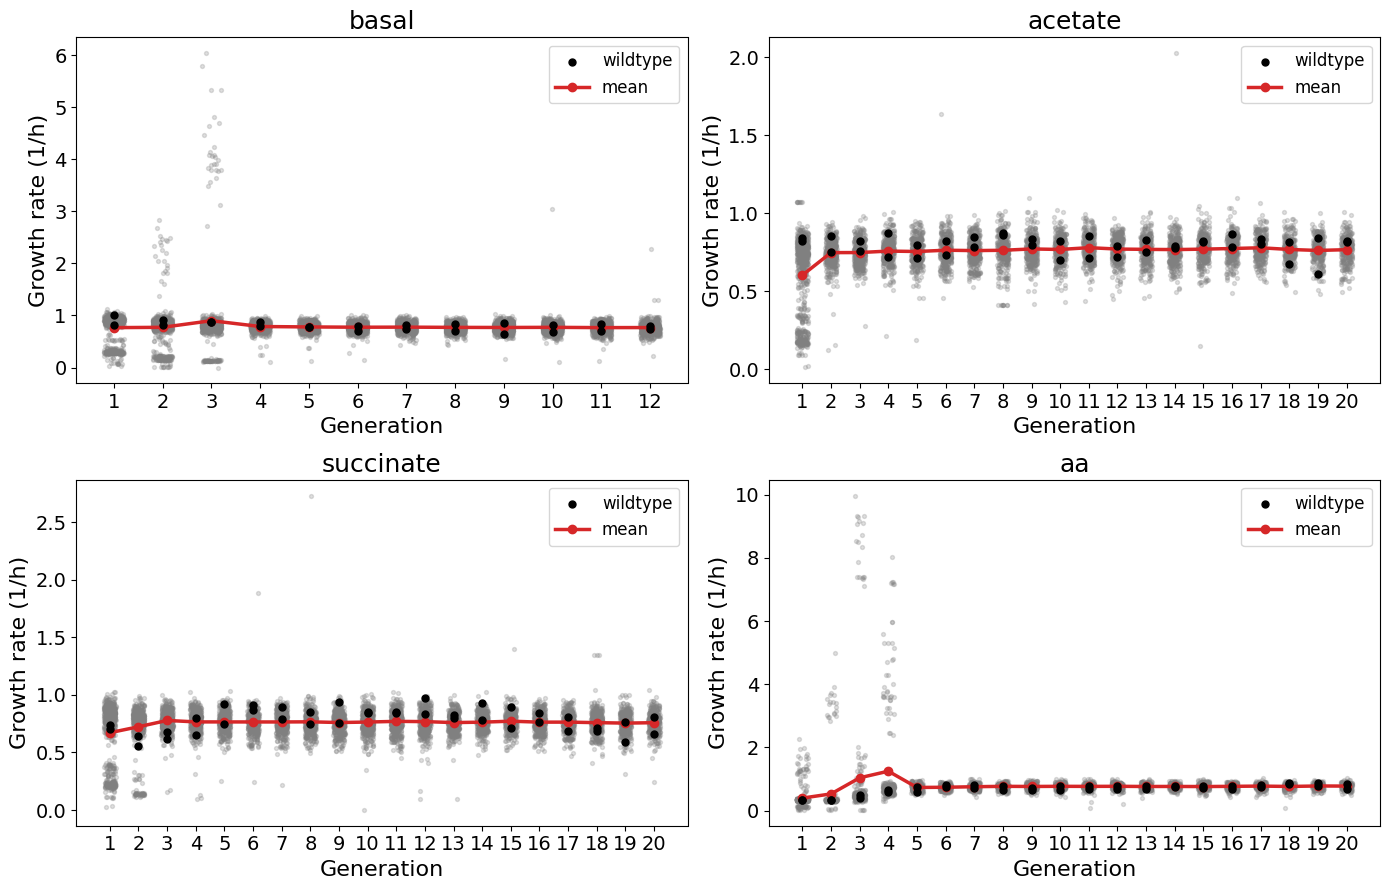

In [5]:
# Step 3: temporal pattern, growth rate (1/h) averaged within each generation
# One point per (KO, seed, generation) from valid runs; the line is the mean over those points.
MAX_GEN_PLOT = {"basal": 12, "acetate": 20, "succinate": 20, "aa": 20}
tp = d[d[TIME] > 0].merge(ps.loc[ps["valid_run"], ["medium", GENE, SEED]], on=["medium", GENE, SEED])
gen_mean = tp.groupby(["medium", GENE, SEED, GEN])[VAL].mean().reset_index(name="gen_mean")
gen_mean = gen_mean[gen_mean[GEN] <= gen_mean["medium"].map(MAX_GEN_PLOT)]
line = gen_mean.groupby(["medium", GEN])["gen_mean"].agg(mean="mean", n_runs="size").reset_index()
line.to_csv(f"{OUT}/step3_generation_mean_growth_rate.csv", index=False)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, ["basal", "acetate", "succinate", "aa"]):
    g = gen_mean[gen_mean["medium"] == m]
    ko_g = g[g[GENE] != WILDTYPE]
    wt_g = g[g[GENE] == WILDTYPE]
    ax.scatter(ko_g[GEN] + rng.uniform(-0.2, 0.2, len(ko_g)), ko_g["gen_mean"], s=8, alpha=0.25, color="grey")
    ax.scatter(wt_g[GEN], wt_g["gen_mean"], s=25, color="black", zorder=5, label="wildtype")
    l = line[line["medium"] == m]
    ax.plot(l[GEN], l["mean"], color="C3", lw=2.5, marker="o", label="mean")
    ax.set_xticks(range(1, MAX_GEN_PLOT[m] + 1))
    ax.set_title(m, fontsize=18)
    ax.set_xlabel("Generation", fontsize=16)
    ax.set_ylabel("Growth rate (1/h)", fontsize=16)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUT}/step3_temporal_pattern.png", dpi=200, bbox_inches="tight")
plt.show()


# Results

## Step 1
1. Completed simulations: early termination differs by medium
Completion rates are basal 75%, succinate 63%, acetate 49% and aa 33%. Most early-ended runs stop at generation 1 (aa: 399 of 625). This is the main thing to account for, because it affects every other table.

2. Time-point level: mean and std are not informative
Medians are similar: they are about 0.19–0.22e-3 (0.67–0.79 /h), with a tight IQR of about 0.05e-3, except aa at 0.11e-3.
Heavy tails: skew and kurtosis are extreme (skew up to 127, kurtosis up to 39,000). A few spikes and negative values, probably around cell division, dominate the mean and std. Use the median and IQR.
Mean below median in every medium: this fits the tail pattern above.
3. Per-seed, all versus completed only
The two tables differ a lot.

4. All simulations: the spread is large (CV 0.37–0.92) and the shapes are mixed.
Completed only: the spread is very small (CV 5–7%, std about 0.000012) in all four media.
Interpretation: the apparent differences between media come mostly from runs that ended early. Steady-state growth is similar across media, with basal highest (0.220e-3) and aa lowest (0.185e-3).

5. Per-KO (all and the 249 shared KOs)
Basal: the median is 0.219e-3 with a tight IQR (0.017e-3). Most KOs grow like the baseline and a few are outliers.
Acetate and succinate: the skew is negative (about -1), and the IQR is larger (about 0.11e-3). A subset of KOs grows slower, which is a bimodal pattern. This could be real, or the first-generation transient of early-ended runs.
aa: the median is 0.142e-3 with a very small IQR (0.014e-3), but the mean is higher and the skew is +3. Most KOs sit in a narrow cluster, plausibly the generation-1 rate, since 399 of 625 runs stop at generation 1. The mean is pulled up by a few KOs with high values. This is my inference and not yet tested.
Shared KOs: restricting to the 249 shared KOs barely changes anything, so the results are not an artefact of different KO sets.

6. Variability
Between-seed CV: the median is 0.036 (basal), 0.044 (succinate) and 0.050 (acetate), so the two seeds agree well. For aa it is 0.44, so the two seeds often disagree. That fits one seed finishing and the other ending early, so aa is the least reproducible.
Within-simulation CV: the median is about 0.2–0.28 in all media. The instantaneous rate is noisy over time, which is expected.
Across-KO CV: aa is 0.79 and the others are 0.39–0.43. The aa spread across KOs reflects the cluster-plus-outliers shape above.